02. Dataset & EDA

[1] Dataset Shape
----------------------------------------------------------------------
Rows    : 436,809
Columns : 3

[2] Columns
----------------------------------------------------------------------
['text', 'label', 'source_file']

[3] Data Types
----------------------------------------------------------------------
text           object
label           int64
source_file    object
dtype: object

[4] Missing Values
----------------------------------------------------------------------
             missing_count  missing_ratio(%)
text                     0               0.0
label                    0               0.0
source_file              0               0.0

[5] Duplicate Analysis
----------------------------------------------------------------------
Duplicate rows  : 687
Duplicate texts : 42,987

[5-1] Duplicate Text Label Consistency
----------------------------------------------------------------------
Duplicated texts with same label : 18,334
Duplicated t

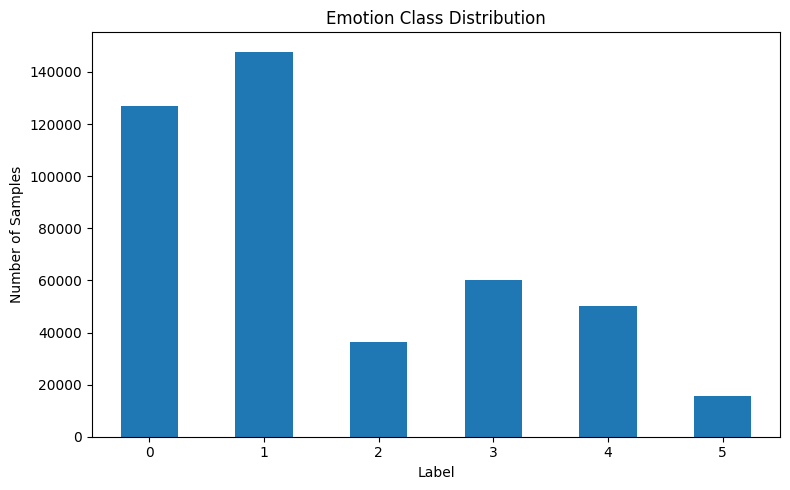

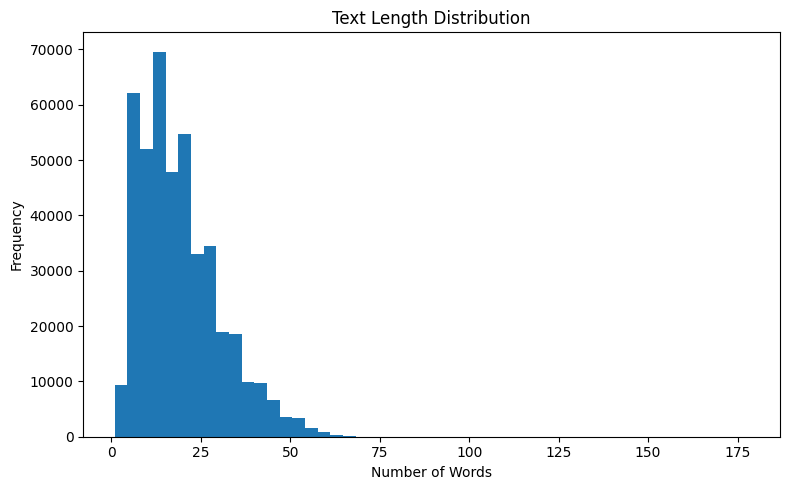

<Figure size 800x500 with 0 Axes>

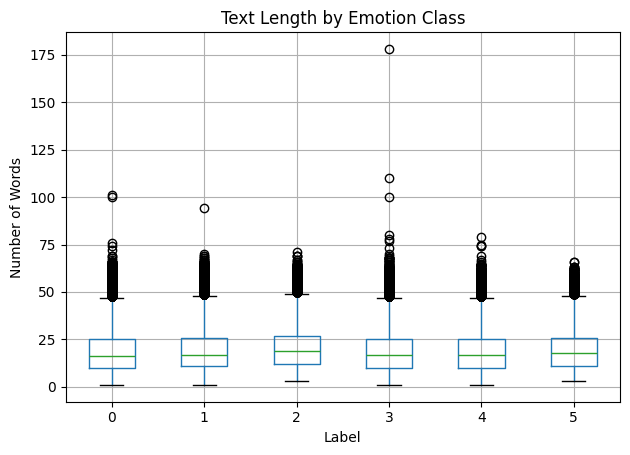

EDA Complete


In [4]:
"""
02. Dataset & EDA
Emotion Classification
"""

import pandas as pd
import matplotlib.pyplot as plt

from utils.config import (
    DATA_PATH,
    TEXT_COL,
    LABEL_COL,
    SEED,
    set_seed
)


# =========================================================
# Reproducibility
# =========================================================

set_seed(SEED)


# =========================================================
# Load Dataset
# =========================================================

df = pd.read_csv(DATA_PATH)


# =========================================================
# Basic Information
# =========================================================

print("=" * 70)
print("02. Dataset & EDA")
print("=" * 70)

print()


# ---------------------------------------------------------
# Dataset Shape
# ---------------------------------------------------------

print("[1] Dataset Shape")
print("-" * 70)

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]:,}")

print()


# ---------------------------------------------------------
# Column Information
# ---------------------------------------------------------

print("[2] Columns")
print("-" * 70)

print(df.columns.tolist())

print()


# ---------------------------------------------------------
# Data Types
# ---------------------------------------------------------

print("[3] Data Types")
print("-" * 70)

print(df.dtypes)

print()


# =========================================================
# Missing Values
# =========================================================

print("[4] Missing Values")
print("-" * 70)

missing_values = df.isnull().sum()

missing_ratio = (
    df.isnull().mean() * 100
)

missing_table = pd.DataFrame({
    "missing_count": missing_values,
    "missing_ratio(%)": missing_ratio
})

print(missing_table)

print()


# =========================================================
# Duplicate Analysis
# =========================================================

print("[5] Duplicate Analysis")
print("-" * 70)

duplicate_rows = df.duplicated().sum()

duplicate_texts = (
    df[TEXT_COL]
    .duplicated()
    .sum()
)

print(f"Duplicate rows  : {duplicate_rows:,}")
print(f"Duplicate texts : {duplicate_texts:,}")

print()


# =========================================================
# Duplicate Text Label Consistency
# =========================================================

print("[5-1] Duplicate Text Label Consistency")
print("-" * 70)

duplicate_text_df = (
    df[
        df[TEXT_COL].duplicated(
            keep=False
        )
    ]
    .sort_values(TEXT_COL)
)

duplicate_text_label_counts = (
    duplicate_text_df
    .groupby(TEXT_COL)[LABEL_COL]
    .nunique()
)

conflicting_texts = (
    duplicate_text_label_counts[
        duplicate_text_label_counts > 1
    ]
)

print(
    f"Duplicated texts with same label : "
    f"{len(duplicate_text_label_counts) - len(conflicting_texts):,}"
)

print(
    f"Duplicated texts with label conflict : "
    f"{len(conflicting_texts):,}"
)

print()

if len(conflicting_texts) > 0:

    print("Example of label-conflicting texts:")
    print()

    conflict_examples = (
        duplicate_text_df[
            duplicate_text_df[TEXT_COL]
            .isin(conflicting_texts.index)
        ]
        .head(20)
    )

    print(
        conflict_examples[
            [
                TEXT_COL,
                LABEL_COL,
                "source_file"
            ]
        ]
        .to_string(index=False)
    )

print()


# =========================================================
# Source File Analysis
# =========================================================

print("[5-2] Source File Analysis")
print("-" * 70)

source_counts = (
    df["source_file"]
    .value_counts()
)

print("Samples by source file:")
print(source_counts)

print()


# ---------------------------------------------------------
# Label Distribution by Source
# ---------------------------------------------------------

source_label_counts = (
    pd.crosstab(
        df["source_file"],
        df[LABEL_COL]
    )
)

print("Label distribution by source file:")
print(source_label_counts)

print()


# ---------------------------------------------------------
# Duplicate Text by Source
# ---------------------------------------------------------

duplicate_source_counts = (
    df[
        df[TEXT_COL].duplicated(
            keep=False
        )
    ]
    .groupby(TEXT_COL)["source_file"]
    .nunique()
)

print(
    "Duplicated texts appearing in multiple source files:"
)

print(
    (duplicate_source_counts > 1).sum()
)

print()


# =========================================================
# Cross-Source Duplicate Analysis
# =========================================================

print("[5-3] Cross-Source Duplicate Analysis")
print("-" * 70)

cross_source_texts = (
    df[
        df[TEXT_COL].duplicated(keep=False)
    ]
    .groupby(TEXT_COL)["source_file"]
    .agg(
        lambda x: sorted(set(x))
    )
)

# 서로 다른 source에 등장하는 텍스트만 선택
cross_source_texts = (
    cross_source_texts[
        cross_source_texts.apply(len) > 1
    ]
)

print(
    f"Texts appearing in multiple sources : "
    f"{len(cross_source_texts):,}"
)

print()

print("Cross-source duplication pattern:")
print()

source_pair_counts = {}

for sources in cross_source_texts:

    for i in range(len(sources)):
        for j in range(i + 1, len(sources)):

            pair = (
                sources[i],
                sources[j]
            )

            source_pair_counts[pair] = (
                source_pair_counts.get(pair, 0) + 1
            )


source_pair_counts = dict(
    sorted(
        source_pair_counts.items(),
        key=lambda x: x[1],
        reverse=True
    )
)

for pair, count in source_pair_counts.items():

    print(
        f"{pair[0]:<20} <-> "
        f"{pair[1]:<20} : "
        f"{count:,}"
    )

print()


# =========================================================
# Label Distribution
# =========================================================

print("[6] Label Distribution")
print("-" * 70)

label_counts = (
    df[LABEL_COL]
    .value_counts()
    .sort_index()
)

print(label_counts)

print()


# =========================================================
# Label Ratio
# =========================================================

print("[7] Label Ratio")
print("-" * 70)

label_ratio = (
    df[LABEL_COL]
    .value_counts(
        normalize=True
    )
    .sort_index()
    * 100
)

label_ratio = label_ratio.round(2)

print(label_ratio)

print()


# =========================================================
# Label Statistics
# =========================================================

print("[8] Label Statistics")
print("-" * 70)

print(f"Number of classes : {df[LABEL_COL].nunique()}")
print(f"Minimum samples   : {label_counts.min():,}")
print(f"Maximum samples   : {label_counts.max():,}")

imbalance_ratio = (
    label_counts.max()
    / label_counts.min()
)

print(
    f"Max / Min ratio   : "
    f"{imbalance_ratio:.2f}"
)

print()


# =========================================================
# Text Length
# =========================================================

df["text_length"] = (
    df[TEXT_COL]
    .astype(str)
    .str.split()
    .str.len()
)


# =========================================================
# Overall Text Length Statistics
# =========================================================

print("[9] Text Length Statistics")
print("-" * 70)

text_length_stats = (
    df["text_length"]
    .describe()
)

print(text_length_stats)

print()


# =========================================================
# Text Length Percentiles
# =========================================================

print("[10] Text Length Percentiles")
print("-" * 70)

percentiles = (
    df["text_length"]
    .quantile(
        [0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print(percentiles)

print()


# =========================================================
# Class-wise Text Length
# =========================================================

print("[11] Class-wise Text Length")
print("-" * 70)

class_text_length = (
    df.groupby(LABEL_COL)["text_length"]
    .agg([
        "count",
        "mean",
        "std",
        "min",
        "median",
        "max"
    ])
    .round(2)
)

print(class_text_length)

print()


# =========================================================
# Class-wise Text Length Percentiles
# =========================================================

print("[12] Class-wise Text Length Percentiles")
print("-" * 70)

class_percentiles = (
    df.groupby(LABEL_COL)["text_length"]
    .quantile(
        [0.90, 0.95, 0.99]
    )
    .unstack()
    .round(2)
)

print(class_percentiles)

print()


# =========================================================
# Sample Data
# =========================================================

print("[13] Sample Data")
print("-" * 70)

print(
    df[
        [
            TEXT_COL,
            LABEL_COL,
            "text_length"
        ]
    ].head(10)
)

print()


# =========================================================
# Visualization 1
# Label Distribution
# =========================================================

plt.figure(figsize=(8, 5))

label_counts.plot(
    kind="bar"
)

plt.title("Emotion Class Distribution")
plt.xlabel("Label")
plt.ylabel("Number of Samples")

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()


# =========================================================
# Visualization 2
# Text Length Distribution
# =========================================================

plt.figure(figsize=(8, 5))

df["text_length"].plot(
    kind="hist",
    bins=50
)

plt.title("Text Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()


# =========================================================
# Visualization 3
# Class-wise Text Length
# =========================================================

plt.figure(figsize=(8, 5))

df.boxplot(
    column="text_length",
    by=LABEL_COL
)

plt.title("Text Length by Emotion Class")
plt.suptitle("")

plt.xlabel("Label")
plt.ylabel("Number of Words")

plt.tight_layout()
plt.show()


# =========================================================
# Summary
# =========================================================

print("=" * 70)
print("EDA Complete")
print("=" * 70)